In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations
from collections import Counter
import os

df = pd.read_parquet("../data/cisto.parquet")

print(f"Ukupno transakcija : {len(df):,}")
print(f"Jedinstvenih računa: {df['InvoiceNo'].nunique():,}")
print(f"Jedinstvenih artikala: {df['StockCode'].nunique():,}")

Ukupno transakcija : 776,579
Jedinstvenih računa: 36,594
Jedinstvenih artikala: 4,620


In [3]:
top_300 = df.groupby("StockCode")["InvoiceNo"].nunique().nlargest(300).index.tolist()
desc_map = df.groupby("StockCode")["Description"].agg(lambda x: x.mode()[0] if not x.empty else "").to_dict()
df_top = df[df.StockCode.isin(top_300)][["InvoiceNo", "StockCode"]].drop_duplicates()

basket = df_top.groupby("InvoiceNo")["StockCode"].apply(set)
n_baskets = len(basket)

print(f"Broj računa koji sadrže bar 1 od top 300 artikala: {n_baskets:,}")
print(f"Procenat pokrivenih računa: {n_baskets / df.InvoiceNo.nunique() * 100:.1f}%")

Broj računa koji sadrže bar 1 od top 300 artikala: 33,081
Procenat pokrivenih računa: 90.4%


In [5]:
item_counts = df_top["StockCode"].value_counts().to_dict()

pair_counts = Counter()
for items in basket:
    if len(items) > 1:
        for a, b in combinations(sorted(items), 2):
            pair_counts[(a, b)] += 1

print(f"Pronađeno jedinstvenih parova artikala: {len(pair_counts):,}")

records = []
for (a, b), count_ab in pair_counts.items():
    supp_ab = count_ab / n_baskets
    supp_a = item_counts[a] / n_baskets
    supp_b = item_counts[b] / n_baskets
    lift = supp_ab / (supp_a * supp_b)
    conf_a_b = count_ab / item_counts[a]
    conf_b_a = count_ab / item_counts[b]
    
    records.append({
        "Artikal_A": a,
        "Naziv_A": desc_map.get(a, a),
        "Artikal_B": b,
        "Naziv_B": desc_map.get(b, b),
        "Zajedno": count_ab,
        "Support": supp_ab,
        "Confidence_A_B": conf_a_b,
        "Confidence_B_A": conf_b_a,
        "Lift": lift
    })

pravila = pd.DataFrame(records)
print(f"Parova sa Lift > 1: {(pravila['Lift'] > 1).sum():,} od ukupno {len(pravila):,}")
print(f"Maksimalni Lift u podacima: {pravila['Lift'].max():.2f}")

Pronađeno jedinstvenih parova artikala: 44,834
Parova sa Lift > 1: 37,740 od ukupno 44,834
Maksimalni Lift u podacima: 37.64


In [6]:
top_pairs = pravila.sort_values("Lift", ascending=False).head(15)

show = top_pairs[["Naziv_A", "Naziv_B", "Zajedno", "Confidence_A_B", "Confidence_B_A", "Lift"]].copy()
show.columns = ["Artikal A", "Artikal B", "Zajedno (računa)", "Conf (A->B)", "Conf (B->A)", "Lift"]
print(show.round(3).to_string(index=False))

                          Artikal A                          Artikal B  Zajedno (računa)  Conf (A->B)  Conf (B->A)   Lift
        SET/6 RED SPOTTY PAPER CUPS      SET/6 RED SPOTTY PAPER PLATES               489        0.787        0.707 37.643
 SET/10 PINK POLKADOT PARTY CANDLES   SET/10 BLUE SPOTTY PARTY CANDLES               480        0.650        0.801 35.871
  FELTCRAFT PRINCESS CHARLOTTE DOLL       FELTCRAFT PRINCESS LOLA DOLL               379        0.610        0.635 33.818
     RED STRIPE CERAMIC DRAWER KNOB    BLUE STRIPE CERAMIC DRAWER KNOB               400        0.651        0.626 33.726
WOODEN HEART CHRISTMAS SCANDINAVIAN WOODEN STAR CHRISTMAS SCANDINAVIAN               469        0.645        0.706 32.140
        FELTCRAFT CUSHION BUTTERFLY           FELTCRAFT CUSHION RABBIT               445        0.655        0.657 32.024
  GARDENERS KNEELING PAD CUP OF TEA   GARDENERS KNEELING PAD KEEP CALM               463        0.729        0.612 31.905
    GREEN REGENCY TEACUP

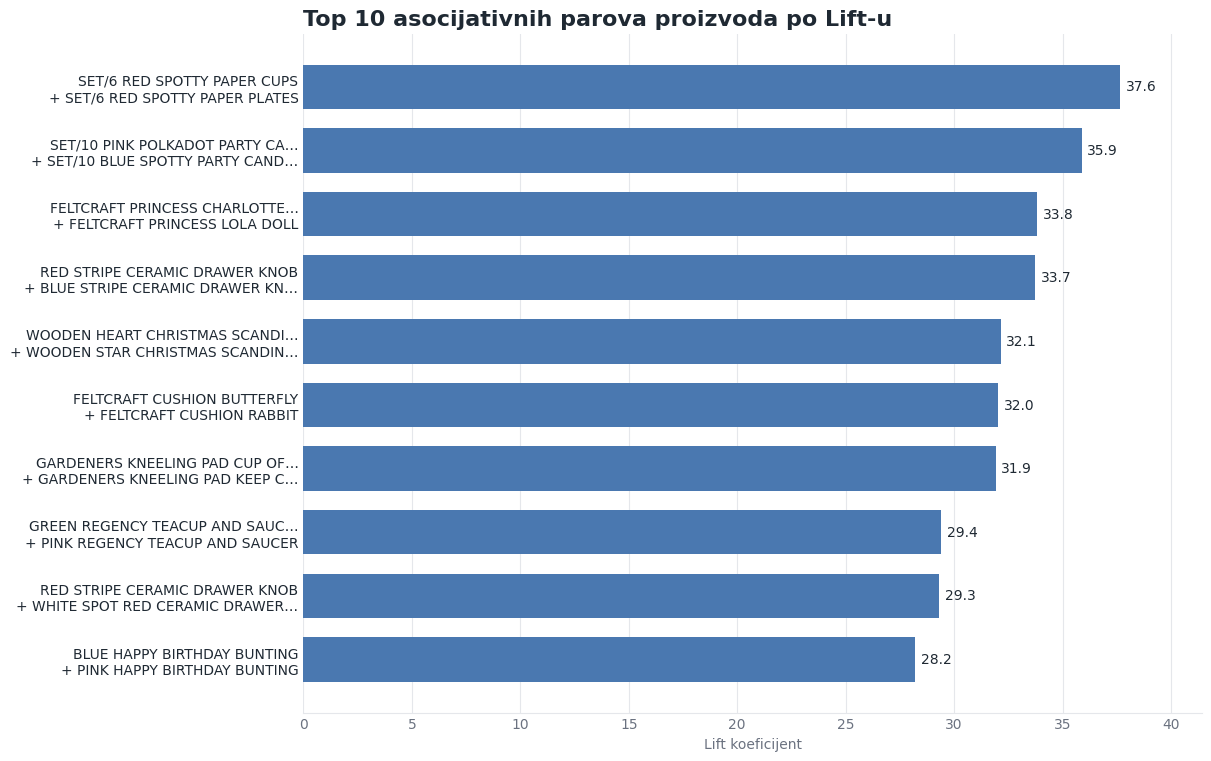

In [7]:
INK, MUTED, GRID = "#1f2933", "#6b7280", "#e5e7eb"
BASE = "#4a78b0"


def shorten(text, n=30):
    return text if len(text) <= n else text[: n - 1].rstrip() + "…"

top_pairs = pravila.sort_values("Lift", ascending=True).tail(10)
labels = [f"{shorten(a)}\n+ {shorten(b)}"
          for a, b in zip(top_pairs["Naziv_A"], top_pairs["Naziv_B"])]

fig, ax = plt.subplots(figsize=(12, 7.5), constrained_layout=True)

bars = ax.barh(labels, top_pairs["Lift"], color=BASE, height=0.7)
ax.bar_label(bars, fmt="%.1f", padding=4, fontsize=10, color=INK)

ax.set_title("Top 10 asocijativnih parova proizvoda po Lift-u", loc="left",
             fontsize=16, fontweight="bold", color=INK)
ax.set_xlabel("Lift koeficijent", color=MUTED)
ax.margins(x=0.1)

ax.tick_params(axis="x", colors=MUTED, length=0)
ax.tick_params(axis="y", labelcolor=INK, labelsize=10, length=0)
ax.set_axisbelow(True)
ax.xaxis.grid(True, color=GRID, linewidth=0.8)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)

plt.show()

In [8]:
def preporuci(sifra_artikla: str, top_n: int = 5):
    sifra = str(sifra_artikla).strip().upper()
    
    deo_a = pravila[pravila.Artikal_A == sifra].copy()
    deo_a["Preporuceni_Kod"] = deo_a["Artikal_B"]
    deo_a["Preporuceni_Naziv"] = deo_a["Naziv_B"]
    deo_a["Confidence"] = deo_a["Confidence_A_B"]
    
    deo_b = pravila[pravila.Artikal_B == sifra].copy()
    deo_b["Preporuceni_Kod"] = deo_b["Artikal_A"]
    deo_b["Preporuceni_Naziv"] = deo_b["Naziv_A"]
    deo_b["Confidence"] = deo_b["Confidence_B_A"]
    
    spojeno = pd.concat([
        deo_a[["Preporuceni_Kod", "Preporuceni_Naziv", "Zajedno", "Confidence", "Lift"]],
        deo_b[["Preporuceni_Kod", "Preporuceni_Naziv", "Zajedno", "Confidence", "Lift"]]
    ])
    
    if spojeno.empty:
        print(f"Nema zabeleženih asocijacija za artikal {sifra} (nije u top 300).")
        return pd.DataFrame()
    
    rezultat = spojeno.sort_values(by=["Lift", "Confidence"], ascending=False).head(top_n).reset_index(drop=True)
    
    naziv_upita = desc_map.get(sifra, sifra)
    print(f"=== PREPORUKE ZA ARTIKAL: {naziv_upita} ({sifra}) ===")
    return rezultat

test_kod_1 = "22998"
preporuke_1 = preporuci(test_kod_1, top_n=5)
print(preporuke_1.round(3).to_string())

print("\n" + "="*70 + "\n")

if "22699" in desc_map:  
    preporuke_2 = preporuci("22699", top_n=5)
    print(preporuke_2.round(3).to_string())

Nema zabeleženih asocijacija za artikal 22998 (nije u top 300).
Empty DataFrame
Columns: []
Index: []


=== PREPORUKE ZA ARTIKAL: ROSES REGENCY TEACUP AND SAUCER (22699) ===
  Preporuceni_Kod                 Preporuceni_Naziv  Zajedno  Confidence    Lift
0           22698    PINK REGENCY TEACUP AND SAUCER      605       0.565  24.774
1           22697   GREEN REGENCY TEACUP AND SAUCER      754       0.705  24.642
2           23245        SET OF 3 REGENCY CAKE TINS      133       0.124   5.727
3           22423          REGENCY CAKESTAND 3 TIER      588       0.550   5.481
4           22907  PACK OF 20 NAPKINS PANTRY DESIGN       89       0.083   4.076


In [9]:
out_path = "../data/pravila_preporuka.parquet"
pravila.to_parquet(out_path, index=False)